# 🤖 OpenCV Computer Vision Workshop

> **A hands-on beginner workshop on Computer Vision using Python, OpenCV, and YOLO.**

**Environment:** Google Colab  
**Approach:** Follow the original workshop sequence. Each concept is broken into small snippets with explanations and activities.

## Important: running this workshop in Colab

Colab runs Python on a remote machine. `cv2.VideoCapture(0)` normally looks for a camera attached to that remote machine, not the camera on your laptop. For camera-based projects, this notebook uses a small browser-camera helper that asks permission and returns a frame to Python. For reliable classroom work, students can also upload a photo or short video recorded on a phone.

**Colab compatibility note:** projects that control the computer's actual mouse or keyboard (Projects 9–11) cannot control the student's local desktop from Colab. They are included in the same learning path, with the limitation clearly marked. The rest of the vision processing can be demonstrated with uploaded images/videos or browser camera frames.

## 📋 Table of Contents

1. What is Computer Vision?
2. What is OpenCV?
3. How OpenCV Works Internally
4. Why Python?
5. Environment Setup
6. Understanding Digital Images
7. Core OpenCV Operations
8. Webcam Video Capture
9. Image Filters & Edge Detection
10. Color Detection
11. Face Detection
12. YOLO Object Detection
13. Workshop Activities
14. Learning Outcomes
15. OpenCV Workshop — Project Collection (Projects 1–11)
16. All Required Libraries
17. Suggested Learning Path
18. Troubleshooting Guide
19. Final activity: test your own Week 2 `.pkl` model

---
## 👁️ What is Computer Vision?

Computer Vision is a field of AI that enables computers to **interpret and understand visual information from the world**.

**Real-world examples**
- 📱 Face unlock in smartphones
- 🚗 Self-driving cars
- 📷 Security surveillance
- 🏥 Medical image analysis
- 🕶️ Augmented reality filters

> **In simple words: Computer Vision = Teaching computers how to see.**

**Think about it:** What visual information would a robot need to detect a person, follow a line, or avoid an obstacle?

---
## 📦 What is OpenCV?

**OpenCV** stands for **Open Source Computer Vision Library**. It provides functions for image processing, detection, tracking, and camera calibration.

| Category | Examples |
|---|---|
| Image Processing | Resize, crop, blur, filter |
| Object Detection | Haar Cascades, HOG detectors |
| Face Detection | Frontal face, eye, smile |
| Motion Tracking | Optical flow |
| Camera Calibration | Lens distortion correction |

Used in robotics, autonomous vehicles, medical imaging, industrial automation, and AI research.

**Key distinction:** OpenCV is a toolkit. It includes traditional computer-vision algorithms and can also be used alongside deep-learning models such as YOLO.

---
## 🧠 How OpenCV Works Internally

OpenCV commonly processes images through a **pipeline**—like a factory assembly line where each stage transforms the image.

```text
Camera Frame
    ↓
Image Acquisition       ← Get an image/frame
    ↓
Image Representation    ← Matrix of numbers
    ↓
Preprocessing           ← Resize, denoise, convert colour
    ↓
Feature Detection       ← Find edges, corners, keypoints
    ↓
Object Detection        ← Haar Cascades / YOLO
    ↓
Visualization           ← Display the result
```

### Human Vision vs Computer Vision

```text
Human:    Eye    → Brain      → Recognize Object
Computer: Camera → OpenCV/AI  → Object Recognition
```

Humans see using eyes and the brain. Computers process camera pixels using mathematics and algorithms.

**Mini-check:** Which pipeline stage would grayscale conversion belong to? (Preprocessing.)

---
## 🐍 Why Python for OpenCV?

- ✅ Simple, readable syntax
- ✅ Rapid prototyping
- ✅ Huge AI/ML ecosystem (NumPy, TensorFlow, PyTorch)
- ✅ Strong community support

We will use Python cells directly in Colab, so students do not need to install PyCharm or create local project folders for this session.

---
## ⚙️ Environment Setup

### 1. Open the notebook in Google Colab

Use **Runtime → Run all** only after reviewing the cells, or run cells one at a time from top to bottom.

### 2. Install the libraries

Colab already provides Python. Run this cell once per fresh runtime.

In [ ]:
%pip -q install opencv-python-headless numpy matplotlib ultralytics

`opencv-python-headless` is used because Colab does not provide a normal desktop display window for `cv2.imshow()`. In this notebook, images are displayed inline with Matplotlib.

### 3. Verify installation

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("OpenCV and NumPy loaded successfully")

OpenCV Version: 4.14.0
NumPy Version: 2.1.3
OpenCV and NumPy loaded successfully


### 4. Notebook project structure

In Colab, uploaded files are stored in the current runtime temporarily. For this workshop, use the upload cells when asked for an image, video, or model file. If you need files to persist, save them to Google Drive or download them before the runtime resets.

---
## 🖼️ Understanding Digital Images

Images are stored as **arrays of numbers (pixels)**.

### Grayscale image

Each pixel is a brightness value from 0 to 255.

```text
120  100   90
200  210  180
 30   40   50
```

| Value | Meaning |
|---:|---|
| `0` | Black |
| `255` | White |

### Colour image (BGR)

OpenCV commonly stores colour channels in **BGR** order rather than RGB.

```python
[255, 0, 0]  # Blue in BGR
[0, 255, 0]  # Green in BGR
[0, 0, 255]  # Red in BGR
```

### Image shape

For an image with 720 rows, 1280 columns, and 3 colour channels, the shape is `(720, 1280, 3)`.

- First value = height
- Second value = width
- Third value = colour channels

In [ ]:
# Create a small example array so we can inspect image dimensions
sample_array = np.zeros((720, 1280, 3), dtype=np.uint8)
print("Image shape:", sample_array.shape)
print("Data type:", sample_array.dtype)

Image shape: (720, 1280, 3)
Data type: uint8


---
## 🔧 Core OpenCV Operations

### Load & display an image

Upload an image from your computer or phone. In Colab, use the upload button shown by the cell below.

Saving god-shiva-nature-art-0ohqqkkb1zd61yq8.webp to god-shiva-nature-art-0ohqqkkb1zd61yq8 (1).webp
Loaded: god-shiva-nature-art-0ohqqkkb1zd61yq8 (1).webp
Shape: (506, 900, 3)


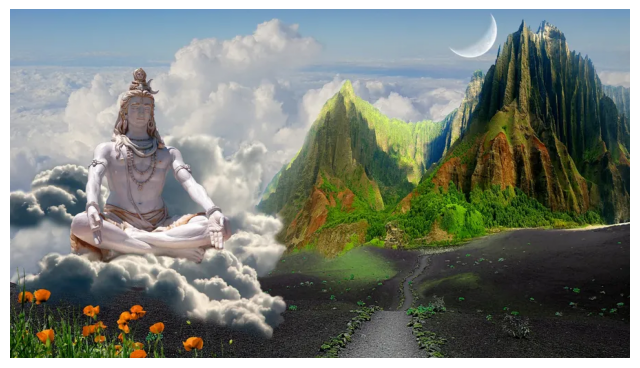

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display
from PIL import Image
import io

uploaded = files.upload()  # Choose a JPG or PNG image
image_name = next(iter(uploaded))
img = cv2.imdecode(np.frombuffer(uploaded[image_name], np.uint8), cv2.IMREAD_COLOR)

print("Loaded:", image_name)
print("Shape:", img.shape)
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off");

In ordinary desktop Python, examples often use `cv2.imshow()`. In Colab, use Matplotlib or `cv2_imshow()` for inline output instead of opening a separate desktop window.

### Convert to grayscale

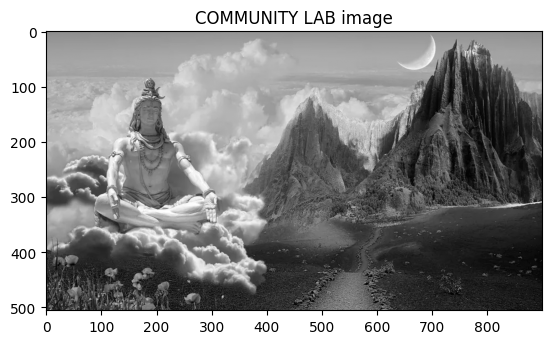

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray, cmap="gray")
plt.title("COMMUNITY LAB image")
plt.axis("on");

Grayscale keeps brightness information but removes the colour channels. Some algorithms, including the Haar face detector below, expect grayscale input.

### Resize image

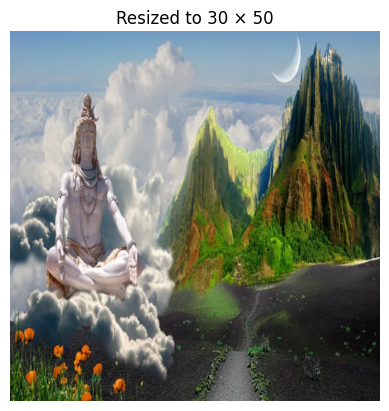

In [ ]:
resized = cv2.resize(img, (740,740))  # (width, height)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized to 30 × 50")
plt.axis("off");

Resizing changes the output dimensions. OpenCV expects `(width, height)` in `cv2.resize()`, while `img.shape` reports `(height, width, channels)`.

### Crop image

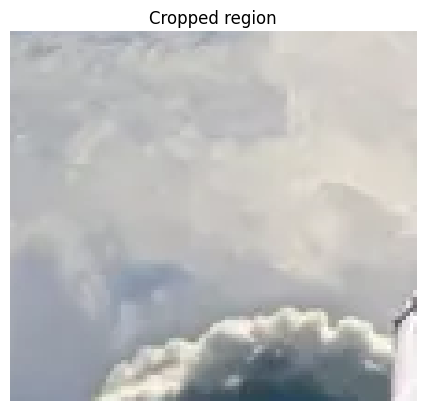

In [ ]:
crop = img[150:250,10:120]  # img[y1:y2, x1:x2]
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Cropped region")
plt.axis("off");

Cropping uses NumPy slicing: rows first (`y`), then columns (`x`). If the selected region is outside the image dimensions, the crop may be smaller or empty.

### Drawing shapes & text

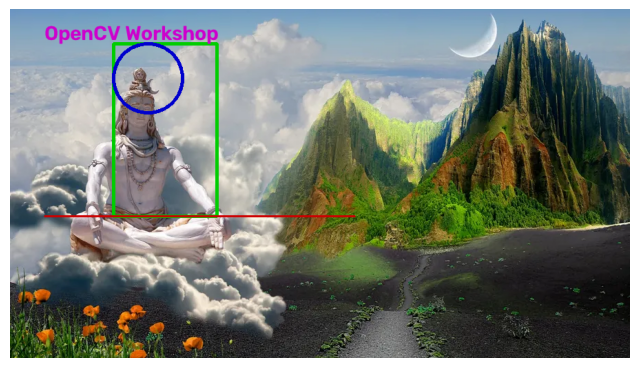

In [ ]:
drawing = img.copy()

# Rectangle
cv2.rectangle(drawing, (150, 50), (300, 300), (0, 205, 0), 3)  # pink

# Circle
cv2.circle(drawing, (200, 100), 50, (205, 0, 0), 3)  # black

# Line
cv2.line(drawing, (50, 300), (500, 300), (0, 0, 205), 2)  # yellow

# Text
cv2.putText(drawing, "OpenCV Workshop", (50, 45),
            cv2.FONT_HERSHEY_SIMPLEX, 1, (205, 0, 205), 2)  # orange

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(drawing, cv2.COLOR_BGR2RGB))
plt.axis("off");

| Function | Purpose |
|---|---|
| `cv2.imread()` | Reads an image from a file path |
| `cv2.cvtColor()` | Converts between colour spaces |
| `cv2.resize()` | Changes image dimensions |
| `cv2.rectangle()` | Draws a rectangle |
| `cv2.circle()` | Draws a circle |
| `cv2.putText()` | Writes text on an image |

**Note:** `cv2.imread()` reads a file path available to the Python runtime. After uploading a file in Colab, use its uploaded name or decode its bytes as demonstrated above.

---
## 📷 Live Video in Google Colab

> **All detection activities below process a continuous live browser-camera feed—not a single captured photo.**

Colab runs Python on a remote machine, so `cv2.VideoCapture(0)` usually cannot access the webcam attached to your laptop. We use the browser's camera permission to stream frames into Python, process each frame with OpenCV/YOLO, and display the result continuously.

Run the next cell once and allow camera access. For each live demo, run its code cell and stop it with the notebook's **Interrupt execution** button (■). Live processing speed depends on your browser, connection, and runtime; YOLO may run more slowly than basic OpenCV filters.


Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.
Upload one sample image for the basic image-processing exercises.


Saving god-shiva-nature-art-0ohqqkkb1zd61yq8.webp to god-shiva-nature-art-0ohqqkkb1zd61yq8 (1).webp
Sample image loaded for image-processing concepts. Detection demos use live video.


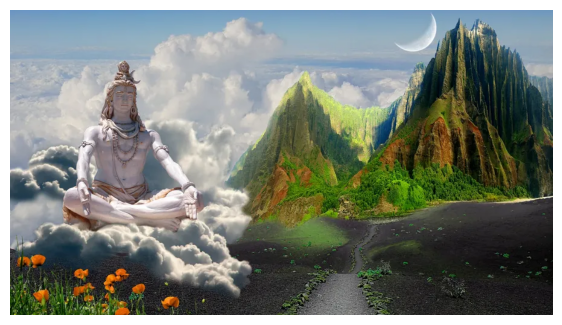

In [ ]:
from IPython.display import Javascript, display
from google.colab.output import eval_js
from base64 import b64decode

def take_browser_photo(filename="browser_photo.jpg", quality=0.9):
    js = Javascript(r'''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const title = document.createElement('p');
      title.textContent = 'Allow camera access, position yourself, then click Capture.';
      div.appendChild(title);
      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.maxWidth = '100%';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      video.srcObject = stream;
      await video.play();
      await new Promise(resolve => {
        const button = document.createElement('button');
        button.textContent = 'Capture photo';
        div.appendChild(button);
        button.onclick = resolve;
        document.body.appendChild(div);
      });
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename



# Reusable live browser-camera loop for every detection project in this notebook.
# The browser sends one current frame at a time to the Colab Python runtime.
import time
from IPython.display import HTML, display
import cv2
import numpy as np

def run_live_video(process_frame, title="Live OpenCV Detection", delay=0.08, max_width=720):
    """Run process_frame(frame_bgr) continuously on live browser-camera frames.
    Stop by clicking Runtime → Interrupt execution (or the ■ stop button).
    """
    setup_js = r"""
    (async () => {
      if (window._mosiCvStream) {
        window._mosiCvStream.getTracks().forEach(t => t.stop());
      }
      const stream = await navigator.mediaDevices.getUserMedia({
        video: { facingMode: 'user', width: {ideal: 640}, height: {ideal: 480} }, audio: false
      });
      const video = document.createElement('video');
      video.autoplay = true; video.muted = true; video.playsInline = true;
      video.srcObject = stream;
      await video.play();
      const canvas = document.createElement('canvas');
      const ctx = canvas.getContext('2d');
      window._mosiCvStream = stream;
      window._mosiCvVideo = video;
      window._mosiCvCanvas = canvas;
      window._mosiCvGetFrame = () => {
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
        return canvas.toDataURL('image/jpeg', 0.72);
      };
      window._mosiCvStop = () => {
        if (window._mosiCvStream) window._mosiCvStream.getTracks().forEach(t => t.stop());
        window._mosiCvStream = null;
        return true;
      };
      return true;
    })()
    """
    eval_js(setup_js)
    output = display(HTML(f'<b>{title}</b><p>Starting live video… interrupt the cell to stop.</p>'), display_id=True)
    try:
        while True:
            data_url = eval_js('window._mosiCvGetFrame()')
            frame_bytes = b64decode(data_url.split(',', 1)[1])
            frame = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
            if frame is None:
                continue
            processed = process_frame(frame)
            if processed is None:
                processed = frame
            h, w = processed.shape[:2]
            if w > max_width:
                processed = cv2.resize(processed, (max_width, int(h * max_width / w)))
            rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
            ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
            if ok:
                import base64
                b64 = base64.b64encode(encoded).decode('ascii')
                output.update(HTML(f'<div><b>{title}</b><br><img style="max-width:100%;height:auto" src="data:image/jpeg;base64,{b64}"><p>Live feed running — use Interrupt execution (■) to stop.</p></div>'))
            time.sleep(delay)
    except KeyboardInterrupt:
        print('Live video stopped.')
    finally:
        try:
            eval_js('window._mosiCvStop && window._mosiCvStop()')
        except Exception:
            pass

print("Live-video helper ready. Each detection demo below starts its own continuous browser-camera stream.")

# Still-image upload is only for the basic image-processing lesson (resize, crop, blur, etc.).
# All detection demos below use live video instead of this uploaded still image.
from google.colab import files
import matplotlib.pyplot as plt

print("Upload one sample image for the basic image-processing exercises.")
image_upload = files.upload()
image_name = next(iter(image_upload))
camera_img = cv2.imdecode(np.frombuffer(image_upload[image_name], np.uint8), cv2.IMREAD_COLOR)
if camera_img is None:
    raise ValueError("Could not read that image. Upload a JPG or PNG file.")
print("Sample image loaded for image-processing concepts. Detection demos use live video.")
plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(camera_img, cv2.COLOR_BGR2RGB))
plt.axis("off");

### How the live video loop works

The helper above repeatedly gets a fresh frame from the browser camera, passes it to an OpenCV/YOLO function, and refreshes the displayed result. Every detection demo uses this loop. You do not need `cv2.VideoCapture(0)` in Colab.

**To stop:** click the notebook's **Interrupt execution** button (■). The helper then stops the browser camera stream. Allow camera permission when prompted.


---
## 🌀 Image Filters & Edge Detection

### Gaussian Blur (noise removal)

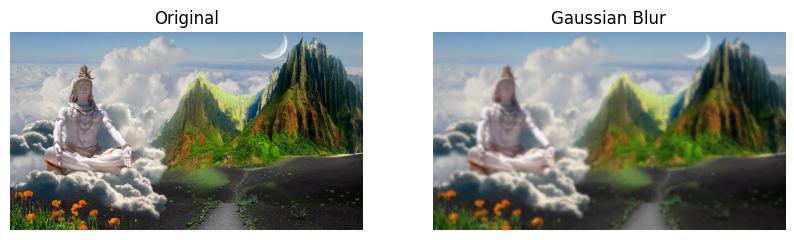

In [ ]:
# Fallback to 'img' if 'camera_img' is not defined
active_img = camera_img if 'camera_img' in globals() else img

blur = cv2.GaussianBlur(active_img, (15, 15), 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(active_img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur")
plt.axis("off");

Gaussian blur smooths small changes in the image. The kernel `(15, 15)` controls the blur size; use odd dimensions such as 5, 15, or 51.

### Canny Edge Detection


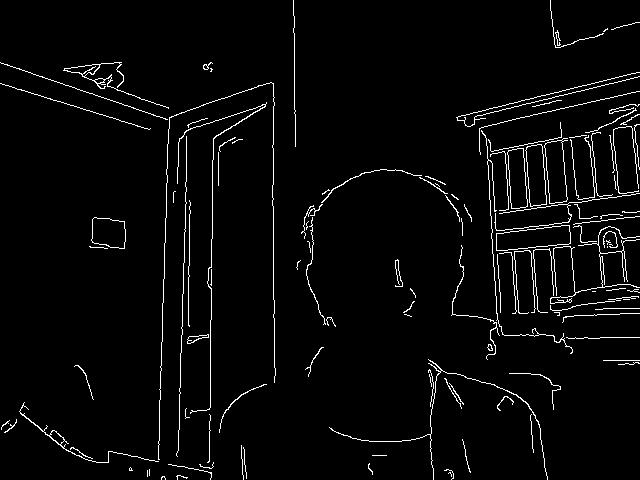

Live video stopped.


In [ ]:
import cv2
import numpy as np

def edge_processor(frame):
    edges = cv2.Canny(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), 100, 200)
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

# Ensure run_live_video is defined, if not, bring it in inline
if 'run_live_video' not in globals():
    from IPython.display import HTML, display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    import time

    def run_live_video(process_frame, title="Live OpenCV Detection", delay=0.08, max_width=720):
        setup_js = r"""
        (async () => {
          if (window._mosiCvStream) {
            window._mosiCvStream.getTracks().forEach(t => t.stop());
          }
          const stream = await navigator.mediaDevices.getUserMedia({
            video: { facingMode: 'user', width: {ideal: 640}, height: {ideal: 480} }, audio: false
          });
          const video = document.createElement('video');
          video.autoplay = true; video.muted = true; video.playsInline = true;
          video.srcObject = stream;
          await video.play();
          const canvas = document.createElement('canvas');
          const ctx = canvas.getContext('2d');
          window._mosiCvStream = stream;
          window._mosiCvVideo = video;
          window._mosiCvCanvas = canvas;
          window._mosiCvGetFrame = () => {
            canvas.width = video.videoWidth; canvas.height = video.videoHeight;
            ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
            return canvas.toDataURL('image/jpeg', 0.72);
          };
          window._mosiCvStop = () => {
            if (window._mosiCvStream) window._mosiCvStream.getTracks().forEach(t => t.stop());
            window._mosiCvStream = null;
            return true;
          };
          return true;
        })()
        """
        eval_js(setup_js)
        output = display(HTML(f'<b>{title}</b><p>Starting live video… interrupt the cell to stop.</p>'), display_id=True)
        try:
            while True:
                data_url = eval_js('window._mosiCvGetFrame()')
                frame_bytes = b64decode(data_url.split(',', 1)[1])
                frame = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
                if frame is None:
                    continue
                processed = process_frame(frame)
                if processed is None:
                    processed = frame
                h, w = processed.shape[:2]
                if w > max_width:
                    processed = cv2.resize(processed, (max_width, int(h * max_width / w)))
                rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
                ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
                if ok:
                    import base64
                    b64 = base64.b64encode(encoded).decode('ascii')
                    output.update(HTML(f'<div><b>{title}</b><br><img style="max-width:100%;height:auto" src="data:image/jpeg;base64,{b64}"><p>Live feed running — use Interrupt execution (■) to stop.</p></div>'))
                time.sleep(delay)
        except KeyboardInterrupt:
            print('Live video stopped.')
        finally:
            try:
                eval_js('window._mosiCvStop && window._mosiCvStop()')
            except Exception:
                pass

run_live_video(edge_processor, "Live Canny Edge Detection")

Edges are boundaries where image brightness changes sharply. In Canny, the two threshold values affect which edges are retained.

**Try it:** change `100, 200` to `50, 150` (more edges may appear) or `150, 250` (fewer edges may remain).

---
## 🎨 Color Detection

RGB is sensitive to lighting. We often use **HSV** because it separates hue (colour) from saturation and brightness.

### Detect blue objects


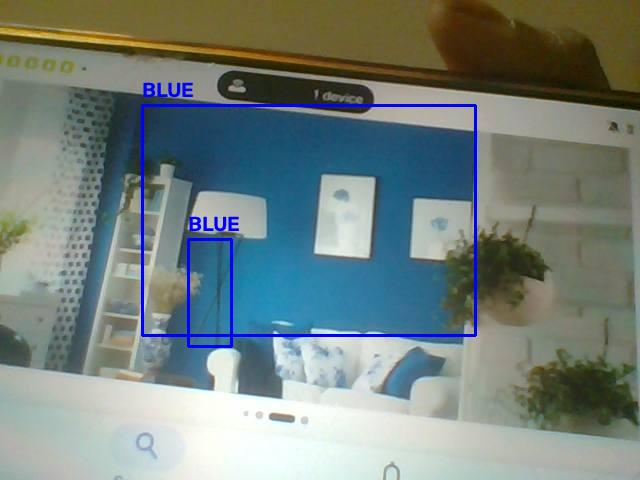

Live video stopped.


In [ ]:
import cv2
import numpy as np

# Ensure run_live_video is defined
if 'run_live_video' not in globals():
    from IPython.display import HTML, display, Javascript
    from google.colab.output import eval_js
    from base64 import b64decode
    import time

    def run_live_video(process_frame, title="Live OpenCV Detection", delay=0.08, max_width=720):
        setup_js = r"""
        (async () => {
          if (window._mosiCvStream) {
            window._mosiCvStream.getTracks().forEach(t => t.stop());
          }
          const stream = await navigator.mediaDevices.getUserMedia({
            video: { facingMode: 'user', width: {ideal: 640}, height: {ideal: 480} }, audio: false
          });
          const video = document.createElement('video');
          video.autoplay = true; video.muted = true; video.playsInline = true;
          video.srcObject = stream;
          await video.play();
          const canvas = document.createElement('canvas');
          const ctx = canvas.getContext('2d');
          window._mosiCvStream = stream;
          window._mosiCvVideo = video;
          window._mosiCvCanvas = canvas;
          window._mosiCvGetFrame = () => {
            canvas.width = video.videoWidth; canvas.height = video.videoHeight;
            ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
            return canvas.toDataURL('image/jpeg', 0.72);
          };
          window._mosiCvStop = () => {
            if (window._mosiCvStream) window._mosiCvStream.getTracks().forEach(t => t.stop());
            window._mosiCvStream = null;
            return true;
          };
          return true;
        })()
        """
        eval_js(setup_js)
        output = display(HTML(f'<b>{title}</b><p>Starting live video… interrupt the cell to stop.</p>'), display_id=True)
        try:
            while True:
                data_url = eval_js('window._mosiCvGetFrame()')
                frame_bytes = b64decode(data_url.split(',', 1)[1])
                frame = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
                if frame is None:
                    continue
                processed = process_frame(frame)
                if processed is None:
                    processed = frame
                h, w = processed.shape[:2]
                if w > max_width:
                    processed = cv2.resize(processed, (max_width, int(h * max_width / w)))
                rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
                ok, encoded = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 75])
                if ok:
                    import base64
                    b64 = base64.b64encode(encoded).decode('ascii')
                    output.update(HTML(f'<div><b>{title}</b><br><img style="max-width:100%;height:auto" src="data:image/jpeg;base64,{b64}"><p>Live feed running — use Interrupt execution (■) to stop.</p></div>'))
                time.sleep(delay)
        except KeyboardInterrupt:
            print('Live video stopped.')
        finally:
            try:
                eval_js('window._mosiCvStop && window._mosiCvStop()')
            except Exception:
                pass

def blue_tracker(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    # Typical range for blue in HSV
    lower_blue = np.array([100, 150, 50])
    upper_blue = np.array([140, 255, 255])
    mask = cv2.inRange(hsv, lower_blue, upper_blue)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    output = frame.copy()
    for cnt in contours:
        if cv2.contourArea(cnt) > 500:
            x, y, w, h = cv2.boundingRect(cnt)
            # BGR for blue is (255, 0, 0)
            cv2.rectangle(output, (x, y), (x+w, y+h), (255, 0, 0), 2)
            cv2.putText(output, "BLUE", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    return output

run_live_video(blue_tracker, "Live Blue Color Tracking")

**How it works**
1. Every live frame is converted from BGR to HSV.
2. A lower and upper blue range define the colour to detect.
3. `cv2.inRange()` creates a mask for blue pixels.
4. Contours are found and bounding boxes are drawn around larger blue regions.

**Try it:** hold a blue object in front of the live camera. To detect red or green, change the HSV range and test under your room lighting.

### `detectMultiScale` parameters

| Parameter | Meaning |
|---|---|
| `scaleFactor=1.3` | Scales the image between search passes |
| `minNeighbors=5` | Higher values generally reduce false positives |

**Try it:** change `minNeighbors=5` to `2` or `8`, then rerun the live cell. Detection may vary with lighting, angle, and image quality.

### Understand the live result

- **Class:** predicted label, such as `person`, `car`, or `bottle`
- **Bounding box:** rectangle around each detected object
- **Confidence:** model confidence for a prediction

| Model | General trade-off | Workshop use |
|---|---|---|
| `yolov8n.pt` | Smallest and fastest | Start here |
| `yolov8s.pt` | Larger, often more accurate | Optional comparison |
| `yolov8m.pt` | Larger and heavier | Optional exploration |

The next cell continuously processes the live browser-camera stream. YOLO can be slower than classical OpenCV detection in a free Colab runtime.

In [ ]:
# This section is intentionally live video, not a one-time camera capture.
# The YOLO model was loaded in the previous cell; rerun that cell to restart live detection.

---
## 🏋️ Workshop Activities

Try these in order—each builds on the last.

| # | Activity | Concepts covered |
|---:|---|---|
| 1 | Load and display an example image | Image reading and display |
| 2 | Convert an image to grayscale | `cvtColor` |
| 3 | Draw shapes and text | `rectangle`, `circle`, `putText` |
| 4 | Run live edge detection | Canny and continuous frames |
| 5 | Track a blue object live | HSV colour space, contours, bounding boxes |
| 6 | Detect faces live | Haar Cascade classifier |
| 7 | Run live YOLO object detection | Deep-learning inference |

**Classroom note:** students need to allow camera permission in the browser. If the browser camera cannot be used, a live-camera demo cannot run in Colab; upload-based media is only a fallback, not a live detection experience.

---
## 4. Motion Detection

> Detects movement by comparing consecutive live video frames.

**Difficulty:** 🟡 Intermediate  
**Concepts:** Frame differencing, thresholding, blur.

```text
Live frame now + previous frame → Absolute difference → Blur → Threshold → Motion mask
```

When a pixel changes enough between consecutive frames, it appears white in the motion mask.


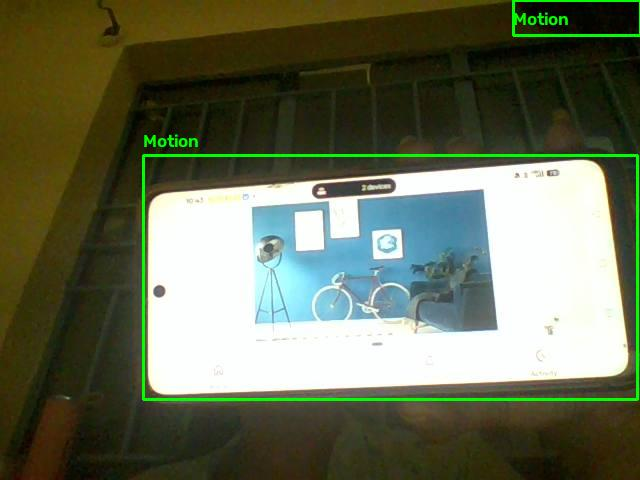

Live video stopped.


In [ ]:
# Project 4: Live Motion Detection

def make_motion_processor():
    previous_gray = {"frame": None}
    def process(frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (5, 5), 0)
        output = frame.copy()
        if previous_gray["frame"] is None:
            previous_gray["frame"] = gray
            cv2.putText(output, "Move in front of camera", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)
            return output
        diff = cv2.absdiff(previous_gray["frame"], gray)
        _, mask = cv2.threshold(diff, 20, 255, cv2.THRESH_BINARY)
        mask = cv2.dilate(mask, None, iterations=2)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            if cv2.contourArea(cnt) > 700:
                x, y, w, h = cv2.boundingRect(cnt)
                cv2.rectangle(output, (x, y), (x+w, y+h), (0,255,0), 2)
                cv2.putText(output, "Motion", (x, max(25, y-8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)
        previous_gray["frame"] = gray
        return output
    return process

run_live_video(make_motion_processor(), "Project 4 — Live Motion Detection")

**Explain the stages**
- `absdiff` compares the current frame with the previous frame.
- Grayscale simplifies the comparison.
- Gaussian blur reduces small noise.
- Thresholding highlights larger changes; contours create motion boxes.

**Try it:** keep the camera still and move one object. Changes in lighting can also trigger motion.

---
## 6. Harry Potter Invisible Cloak

> Detects red cloth in a live video feed and replaces those pixels with a saved empty-background image.

**Difficulty:** 🟡 Intermediate  
**Concepts:** Background image, HSV mask, bitwise operations, morphology.

```text
Upload empty background once → Live camera frames → Detect red cloth → Replace red pixels
```

Keep the camera in the same position for the background and live video. Use a bright red cloth and steady lighting.

Upload ONE image of the empty background (no person or red cloth).


Saving WIN_20261111_22_58_29_Pro.jpg to WIN_20261111_22_58_29_Pro.jpg



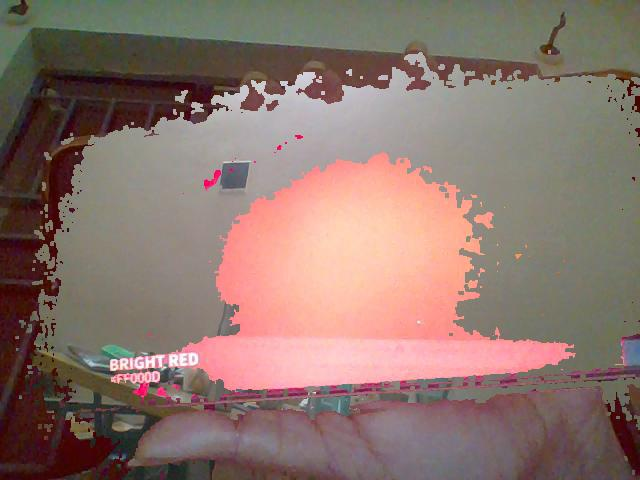

Live video stopped.


In [ ]:
# Project 6: Live Invisible Cloak
from google.colab import files

print("Upload ONE image of the empty background (no person or red cloth).")
bg_upload = files.upload()
bg_name = next(iter(bg_upload))
background_original = cv2.imdecode(np.frombuffer(bg_upload[bg_name], np.uint8), cv2.IMREAD_COLOR)

def cloak_processor(frame):
    background = cv2.resize(background_original, (frame.shape[1], frame.shape[0]))
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    lower_red1, upper_red1 = np.array([0, 120, 70]), np.array([10, 255, 255])
    lower_red2, upper_red2 = np.array([170, 120, 70]), np.array([180, 255, 255])
    mask = cv2.bitwise_or(cv2.inRange(hsv, lower_red1, upper_red1), cv2.inRange(hsv, lower_red2, upper_red2))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
    mask_inv = cv2.bitwise_not(mask)
    bg_part = cv2.bitwise_and(background, background, mask=mask)
    fg_part = cv2.bitwise_and(frame, frame, mask=mask_inv)
    return cv2.add(bg_part, fg_part)

run_live_video(cloak_processor, "Project 6 — Live Invisible Cloak")

**What each step does**
- Upload an empty background image once; this is not a camera capture.
- HSV masking isolates red pixels in each live frame.
- Morphology removes some small specks.
- Bitwise operations replace red regions with pixels from the empty background.

**Tips:** keep the camera fixed, use a bright red cloth, and avoid red objects elsewhere in the scene. The effect will look imperfect if the background or camera moves.

---
## 8. Object Counter using YOLO

> Counts objects detected in each live video frame.

**Difficulty:** 🟡 Intermediate  
**Concepts:** YOLO output, bounding-box count, text overlay.

In [ ]:
%pip install -q ultralytics
from ultralytics import YOLO

# Initialize YOLO model here so that Project 8 can find and use it
try:
    if 'model' not in globals():
        model = YOLO('yolov8n.pt')
        print('YOLO model loaded successfully for the Object Counter!')
except Exception as e:
    print('Error loading YOLO model:', e)


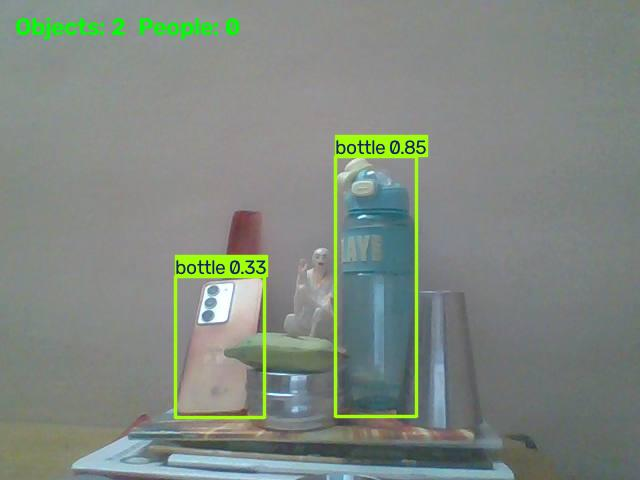

Live video stopped.


In [ ]:
# Project 8: Live YOLO Object Counter

def yolo_counter_processor(frame):
    result = model(frame, verbose=False)[0]
    annotated = result.plot()
    count = len(result.boxes)
    people = sum(1 for box in result.boxes if int(box.cls[0]) == 0)
    cv2.putText(annotated, f"Objects: {count}  People: {people}", (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return annotated

run_live_video(yolo_counter_processor, "Project 8 — Live YOLO Object Counter", delay=0.12)

`len(result.boxes)` counts the detected bounding boxes in the current frame. It is not a count of unique physical objects across time: one moving object can appear in many consecutive frames.

**Count only people:** in the standard COCO model, class ID `0` represents `person`. The live overlay displays both the total boxes and people in each frame.

In [ ]:
# Optional: inside the live processor, person_count is calculated as:
# person_count = sum(1 for box in result.boxes if int(box.cls[0]) == 0)
# The live counter above displays this value on every frame.

---
## 🚀 YOLO Object Detection

**YOLO** means “You Only Look Once.” It is a deep-learning model that predicts object classes, bounding boxes, and confidence scores.

YOLO can detect common classes such as people, cars, bottles, phones, chairs, and animals.

### Classical CV vs AI vision

| Approach | Pipeline |
|---|---|
| Classical OpenCV | Image → hand-crafted features/rules → detection |
| Deep learning (YOLO) | Image → neural network → object detections |

### Run YOLO on an image

The first run downloads the model weights. This may take a little time and requires an internet connection in the Colab runtime.


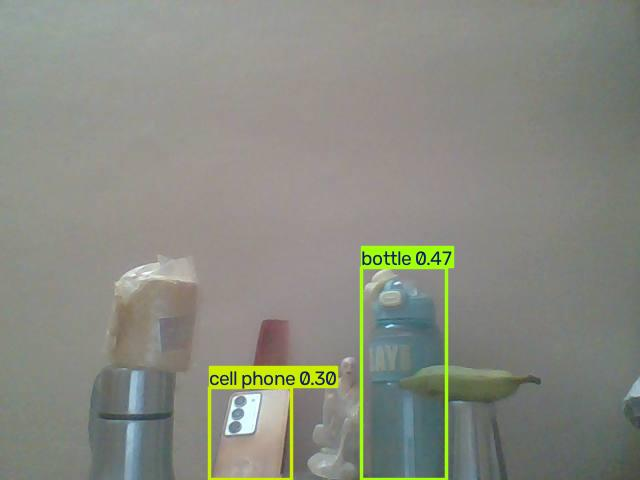

Live video stopped.


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # small, fast model

def yolo_processor(frame):
    result = model(frame, verbose=False)[0]
    return result.plot()

run_live_video(yolo_processor, "Live YOLO Object Detection", delay=0.12)